# Завдання 1. Поширення релевантності в часі та збіжність

**Пункт 1 ТЗ.** Дослідити, як розподіл релевантності від вузла запиту змінюється зі збільшенням кроків (часу): швидкість поширення та збіжність до стаціонарного розподілу. Встановити зв'язок швидкості збіжності з параметром α і спектром матриці переходів.

Розрізняємо дві границі:
- ітерації PPR π_{k+1} = α·s + (1 − α)·π_k·P збігаються до π* (залежить від вузла запиту);
- блукання без перезапуску π_{k+1} = π_k·P і теплове ядро u(t) = s·e^(−tL) збігаються до d/Σd (не залежить від запиту).

Теоретичні швидкості (λ — власні значення P, |λ|₍₂₎ — друге за модулем, λ₂ — друге за величиною):

| процес | похибка спадає як |
|---|---|
| ітерації PPR | ((1 − α)·|λ|₍₂₎)^k, гарантовано не повільніше (1 − α)^k |
| блукання без перезапуску | |λ|₍₂₎^k |
| ліниве блукання | ((1 + λ₂)/2)^k |
| теплове ядро | e^(−t(1 − λ₂)) |

In [1]:
from pathlib import Path
import time

import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from reldiff.api import rank, spectrum
from reldiff import graphs as G
from reldiff import metaqa as MQ

FIG = Path("../figures"); RES = Path("../results")
N_SEEDS = 20
rng = np.random.default_rng(0)

# Графи (усі неорієнтовані, незважені)
GR = {
    "ER": G.erdos_renyi(1000, 0.01, seed=1),
    "WS p=0.01": G.watts_strogatz(1000, 10, 0.01, seed=2),
    "WS p=0.1": G.watts_strogatz(1000, 10, 0.1, seed=3),
    "WS p=1": G.watts_strogatz(1000, 10, 1.0, seed=4),
    "BA": G.barabasi_albert(1000, 5, seed=5),
    "SBM p_out=0.0005": G.sbm([500, 500], 0.02, 0.0005, seed=6),
    "SBM p_out=0.002": G.sbm([500, 500], 0.02, 0.002, seed=7),
    "SBM p_out=0.01": G.sbm([500, 500], 0.02, 0.01, seed=8),
    "ланцюжок P₁₀₀": G.path(100),
    "цикл C₁₀₀": G.cycle(100),
}
g_mq, q_mq, _ = MQ.load_processed("../data/metaqa", 500, 0)
GR["MetaQA"] = g_mq

# Вузли запиту: 20 випадкових; на MetaQA — 10 фільмів і 10 людей серед сутностей запиту питань
SEEDS = {}
for name, g in GR.items():
    if name == "MetaQA":
        movies = sorted({t for t in q_mq.topic if "movie" in g.nodes[t]["kinds"]})
        people = sorted({t for t in q_mq.topic if {"actor", "director", "writer"} & set(g.nodes[t]["kinds"])
                         and "movie" not in g.nodes[t]["kinds"]})
        SEEDS[name] = list(rng.choice(movies, 10, replace=False)) + list(rng.choice(people, 10, replace=False))
    else:
        nodes = list(g.nodes())
        SEEDS[name] = [nodes[i] for i in rng.choice(len(nodes), N_SEEDS, replace=False)]

def dist_vector(g, q):
    # відстані (кількість ребер) від q до всіх вузлів у порядку rank
    d = nx.single_source_shortest_path_length(g, q)
    return np.array([d.get(v, np.inf) for v in g.nodes()], dtype=float)

def stationary(g):
    d = rank(g, next(iter(g)), "ppr", return_info=True)[1]["degrees"].to_numpy()
    return d / d.sum()

rows = []
SPEC = {}
for name, g in GR.items():
    t0 = time.perf_counter()
    lam, s = spectrum(g, return_summary=True)
    SPEC[name] = (lam, s)
    rows.append(dict(граф=name, n=g.number_of_nodes(), ребер=g.number_of_edges(),
                     дводольний=nx.is_bipartite(nx.Graph(g)), λ2=s["lambda_2"], λ_min=s["lambda_min"],
                     модуль_λ2=s["modulus_2"], щілина=s["gap"], ліниве=s["lazy_rate"],
                     час_с=time.perf_counter() - t0))
tab_spec = pd.DataFrame(rows)
tab_spec.to_csv(RES / "01_spektr_grafiv.csv", index=False)
pd.set_option("display.float_format", "{:.6g}".format)
display(tab_spec)

,граф,n,ребер,дводольний,λ2,λ_min,модуль_λ2,щілина,ліниве,час_с
0,ER,1000,4962,False,0.598388,-0.605309,0.605309,0.401612,0.799194,0.087202
1,WS p=0.01,1000,5000,False,0.994768,-0.381122,0.994768,0.0052315,0.997384,0.134379
2,WS p=0.1,1000,5000,False,0.95198,-0.465048,0.95198,0.04802,0.97599,0.0648063
3,WS p=1,1000,5000,False,0.595905,-0.596609,0.596609,0.404095,0.797953,0.0743021
4,BA,1000,4975,False,0.575623,-0.579932,0.579932,0.424377,0.787811,0.07915
5,SBM p_out=0.0005,1000,5064,False,0.958665,-0.589575,0.958665,0.0413353,0.979332,0.0859855
6,SBM p_out=0.002,1000,5440,False,0.858911,-0.568407,0.858911,0.141089,0.929455,0.0802714
7,SBM p_out=0.01,1000,7407,False,0.506685,-0.49389,0.506685,0.493315,0.753342,0.0861141
8,ланцюжок P₁₀₀,100,99,True,0.999497,-1,1,0.000503458,0.999748,0.0151553
9,цикл C₁₀₀,100,100,True,0.998027,-1,1,0.00197327,0.999013,0.00264715


## Завдання 1.1. Як поширюється релевантність

Для кожного розподілу π рахуємо:
- **масу за відстанню** M_r = Σ_{i: dist(q, i) = r} π_i;
- **середню відстань маси** d̄ = Σ_i π_i·dist(q, i);
- **радіус 90% маси** — найменше r, за якого Σ_{ρ ≤ r} M_ρ ≥ 0.9;
- **ефективну кількість вузлів** exp(H(π)).

Процеси: ітерації PPR (α = 0.15) і блукання без перезапуску за кроками k, теплове ядро за часом t.

**Очікування:**
- Дискретний процес має **скінченну швидкість поширення**: π_k ненульова лише в межах k ребер від q.
- У теплового ядра при малих t маса на відстані r має асимптотику M_r(t) ≈ e^(−t)·(t^r/r!)·(s·P^r)(сфера радіуса r) — це перший член ряду. Отже, log M_r ≈ r·log t + const, і при t > 0 маса є в усіх досяжних вузлах.
- Для PPR (1 − α)/α — **середня довжина блукання**, а не середня відстань. Блукання повертаються назад, тому d̄(π*) ≤ (1 − α)/α. Відношення d̄/((1 − α)/α) показує, наскільки граф «повертає» блукання.

In [2]:
def profile(pi, dist, r_max):
    # маса на відстанях 0..r_max і останній елемент — сумарна маса далі (r > r_max)
    return np.array([pi[dist == r].sum() for r in range(r_max + 1)] + [pi[dist > r_max].sum()])

def spread_metrics(pi, dist):
    pi = np.clip(pi, 0, None); fin = np.isfinite(dist)
    mean_d = (pi[fin] * dist[fin]).sum()
    order = np.argsort(dist); cum = np.cumsum(pi[order])
    r90 = dist[order][np.searchsorted(cum, 0.9 - 1e-12)]
    p = pi[pi > 0]; H = -(p * np.log(p)).sum()
    return mean_d, r90, np.exp(H), (pi > 0).sum()

SHOW = ["ER", "WS p=0.01", "MetaQA"]
K_MAX, T_GRID = 40, np.linspace(0, 40, 81)
ALPHA = 0.15
R_SHOW = 6

traj = {}
for name in SHOW:
    g = GR[name]
    res = {"ppr": [], "walk": [], "heat": []}
    for q in SEEDS[name]:
        dist = dist_vector(g, q)
        tr = rank(g, q, "ppr", alpha=ALPHA, solver="iterative", tol=1e-14, keep_trajectory=True,
                  return_info=True)[1]["trajectory"]
        tr = np.vstack([tr, np.repeat(tr[-1:], max(0, K_MAX + 1 - len(tr)), axis=0)])[:K_MAX + 1]
        tw = rank(g, q, "walk", steps=K_MAX, keep_trajectory=True, return_info=True)[1]["trajectory"]
        th = np.array([rank(g, q, "heat", t=t).to_numpy() for t in T_GRID])
        for key, T in (("ppr", tr), ("walk", tw), ("heat", th)):
            res[key].append(dict(profile=np.array([profile(p, dist, R_SHOW) for p in T]),
                                 metrics=np.array([spread_metrics(p, dist) for p in T])))
    traj[name] = res
print("Готово: профілі для", SHOW)

Готово: профілі для ['ER', 'WS p=0.01', 'MetaQA']


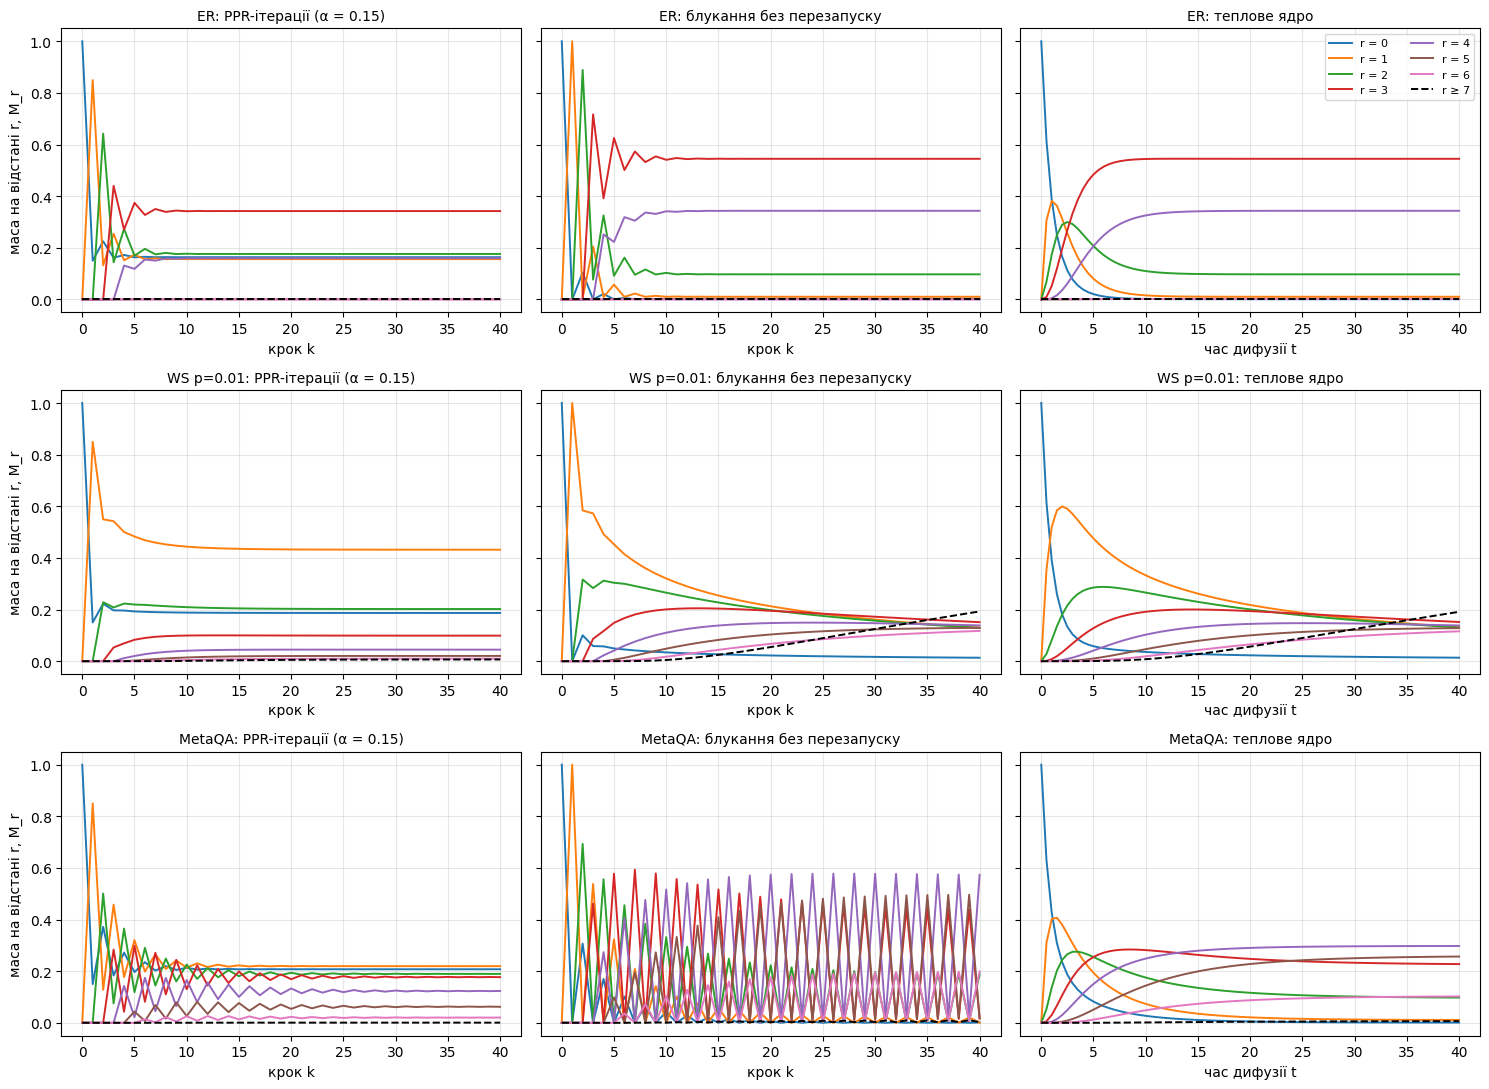

Сума кривих (r = 0…6 і r ≥ 7) відрізняється від 1 не більше ніж на 4.0e-15


In [3]:
fig, axs = plt.subplots(3, 3, figsize=(15, 11), sharey=True)
max_dev = 0.0
for i, name in enumerate(SHOW):
    for j, (key, xs, xl) in enumerate((("ppr", np.arange(K_MAX + 1), "крок k"),
                                       ("walk", np.arange(K_MAX + 1), "крок k"),
                                       ("heat", T_GRID, "час дифузії t"))):
        ax = axs[i, j]
        prof = np.mean([r["profile"] for r in traj[name][key]], axis=0)   # середнє за 20 вузлами запиту
        for r in range(R_SHOW + 1):
            ax.plot(xs, prof[:, r], lw=1.4, label=f"r = {r}")
        ax.plot(xs, prof[:, -1], "k--", lw=1.4, label=f"r ≥ {R_SHOW + 1}")
        max_dev = max(max_dev, np.abs(prof.sum(axis=1) - 1).max())
        ax.set_xlabel(xl); ax.grid(alpha=0.3)
        title = {"ppr": f"PPR-ітерації (α = {ALPHA})", "walk": "блукання без перезапуску", "heat": "теплове ядро"}[key]
        ax.set_title(f"{name}: {title}", fontsize=10)
        if j == 0: ax.set_ylabel("маса на відстані r, M_r")
axs[0, 2].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig(FIG / "01_masa_za_vidstannyu.png", dpi=200); plt.show()
print(f"Сума кривих (r = 0…{R_SHOW} і r ≥ {R_SHOW + 1}) відрізняється від 1 не більше ніж на {max_dev:.1e}")

Тепер середня відстань, радіус 90% маси й ефективна кількість вузлів (середнє за 20 вузлами запиту). Окремо — перевірка скінченної швидкості дискретного процесу: кількість ненульових вузлів π_k не перевищує розміру кулі радіуса k.

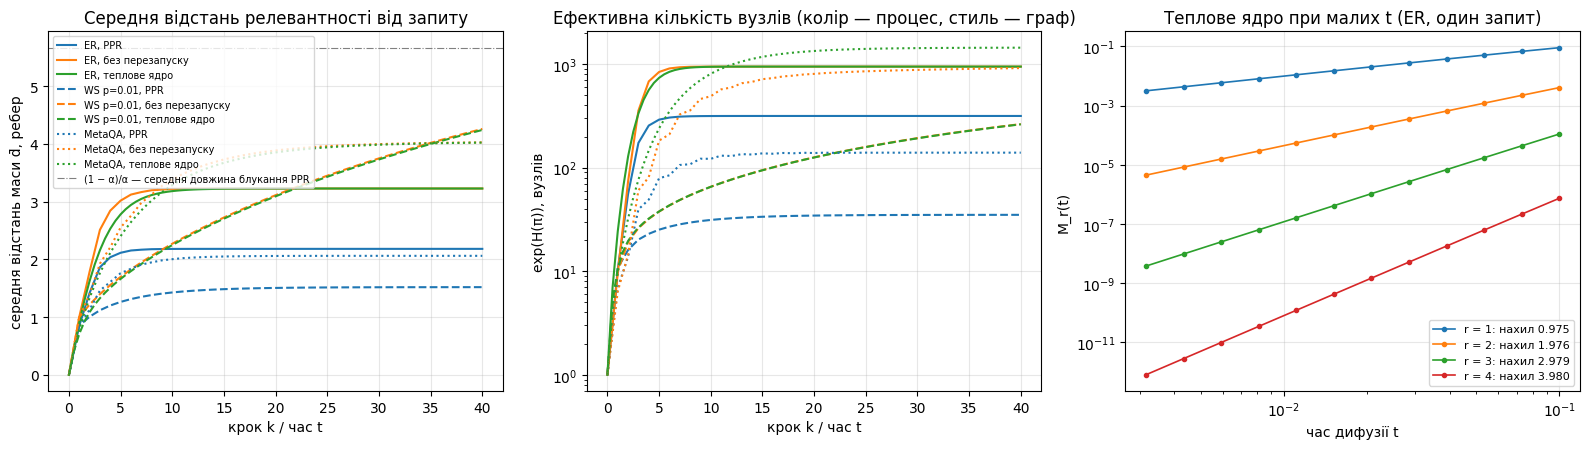

Нахили log M_r від log t при малих t (теорія: r): [0.9753 1.976  2.979  3.9795]
Випадків, коли π_k має масу далі ніж k ребер від запиту: 0
Теплове ядро на ER: ненульових вузлів при t = 0.5: 1000 з 1000


In [4]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
for name, ls in zip(SHOW, ("-", "--", ":")):
    for key, xs, c in (("ppr", np.arange(K_MAX + 1), "C0"), ("walk", np.arange(K_MAX + 1), "C1"),
                       ("heat", T_GRID, "C2")):
        m = np.mean([r["metrics"] for r in traj[name][key]], axis=0)
        lab = {"ppr": "PPR", "walk": "без перезапуску", "heat": "теплове ядро"}[key]
        axs[0].plot(xs, m[:, 0], ls, color=c, lw=1.5, label=f"{name}, {lab}")
        axs[1].plot(xs, m[:, 2], ls, color=c, lw=1.5)
axs[0].axhline((1 - ALPHA) / ALPHA, color="gray", lw=0.8, ls="-.", label="(1 − α)/α — середня довжина блукання PPR")
axs[0].set_xlabel("крок k / час t"); axs[0].set_ylabel("середня відстань маси d̄, ребер")
axs[0].set_title("Середня відстань релевантності від запиту"); axs[0].legend(fontsize=7)
axs[1].set_yscale("log"); axs[1].set_xlabel("крок k / час t"); axs[1].set_ylabel("exp(H(π)), вузлів")
axs[1].set_title("Ефективна кількість вузлів (колір — процес, стиль — граф)")

# Мала t: перший член ряду M_r(t) ≈ e^(−t)·t^r/r!·(s·P^r)(сфера r)  =>  нахил log M_r від log t = r
ts = np.logspace(-2.5, -1, 12)
g = GR["ER"]; q = SEEDS["ER"][0]; dist = dist_vector(g, q)
slopes = []
for r in range(1, 5):
    M = np.array([profile(rank(g, q, "heat", t=t, solver="series").to_numpy(), dist, r)[r] for t in ts])
    k = np.polyfit(np.log(ts), np.log(M), 1)[0]; slopes.append(k)
    axs[2].loglog(ts, M, "o-", ms=3, lw=1.2, label=f"r = {r}: нахил {k:.3f}")
axs[2].set_xlabel("час дифузії t"); axs[2].set_ylabel("M_r(t)")
axs[2].set_title("Теплове ядро при малих t (ER, один запит)"); axs[2].legend(fontsize=8)
for ax in axs: ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG / "01_shvydkist_poshyrennya.png", dpi=200); plt.show()
print("Нахили log M_r від log t при малих t (теорія: r):", np.round(slopes, 4))

# Скінченна швидкість: |supp π_k| ≤ |кулі радіуса k|
viol = 0
for name in SHOW:
    g = GR[name]
    for q in SEEDS[name][:5]:
        dist = dist_vector(g, q)
        tr = rank(g, q, "ppr", alpha=ALPHA, solver="iterative", keep_trajectory=True, return_info=True)[1]["trajectory"]
        for k in range(min(8, len(tr))):
            viol += int(np.any(tr[k][dist > k] > 0))
print(f"Випадків, коли π_k має масу далі ніж k ребер від запиту: {viol}")
th = traj["ER"]["heat"][0]["metrics"]
print(f"Теплове ядро на ER: ненульових вузлів при t = {T_GRID[1]:.1f}: {th[1, 3]:.0f} з {GR['ER'].number_of_nodes()}")

Середня відстань у стаціонарному розподілі PPR π* проти середньої довжини блукання (1 − α)/α для різних графів і α. Для порівняння наводимо також середню відстань маси в d/Σd (межа α → 0) і в тепловому ядрі при t = (1 − α)/α (та сама середня довжина блукання).

In [5]:
rows = []
for name, g in GR.items():
    pi_inf = stationary(g)
    for alpha in (0.05, 0.15, 0.5):
        L = (1 - alpha) / alpha
        dp, dh, dinf = [], [], []
        for q in SEEDS[name]:
            dist = dist_vector(g, q)
            dp.append(spread_metrics(rank(g, q, "ppr", alpha=alpha).to_numpy(), dist)[0])
            dh.append(spread_metrics(rank(g, q, "heat", t=L).to_numpy(), dist)[0])
            dinf.append(spread_metrics(pi_inf, dist)[0])
        rows.append(dict(граф=name, α=alpha, сер_довжина_блукання=L, d_PPR=np.mean(dp),
                         відношення=np.mean(dp) / L, d_тепл_t_рівне_L=np.mean(dh), d_для_dΣd=np.mean(dinf)))
tab_spread = pd.DataFrame(rows)
tab_spread.to_csv(RES / "01_poshyrennya.csv", index=False)
pd.set_option("display.float_format", "{:.3f}".format)
display(tab_spread.pivot_table(index="граф", columns="α", values=["d_PPR", "відношення"], sort=False))
print(f"Максимальне відношення d̄(π*)/((1−α)/α): {tab_spread['відношення'].max():.3f}")

d_PPR             відношення            
α                0.050 0.150 0.500      0.050 0.150 0.500
граф                                                     
ER               2.832 2.181 0.815      0.149 0.385 0.815
WS p=0.01        2.656 1.518 0.595      0.140 0.268 0.595
WS p=0.1         2.996 1.861 0.660      0.158 0.328 0.660
WS p=1           2.859 2.201 0.820      0.150 0.388 0.820
BA               2.587 2.029 0.796      0.136 0.358 0.796
SBM p_out=0.0005 2.821 2.114 0.802      0.148 0.373 0.802
SBM p_out=0.002  2.772 2.130 0.810      0.146 0.376 0.810
SBM p_out=0.01   2.501 1.997 0.807      0.132 0.352 0.807
ланцюжок P₁₀₀    2.947 1.595 0.577      0.155 0.281 0.577
цикл C₁₀₀        3.042 1.614 0.577      0.160 0.285 0.577
MetaQA           3.101 2.061 0.698      0.163 0.364 0.698

Максимальне відношення d̄(π*)/((1−α)/α): 0.820


## Завдання 1.2. Збіжність ітерацій PPR до π* і роль α

Для кожного графа, α ∈ {0.05, 0.1, 0.15, 0.3, 0.5} і 20 вузлів запиту рахуємо похибку ‖π_k − π*‖₁ (π* — з лінійної системи). Фактичну швидкість ρ̂ оцінюємо за нахилом ln‖π_k − π*‖₁ на ділянці, де похибка між 10⁻¹¹ і 10⁻³. Її порівнюємо з асимптотикою (1 − α)·|λ|₍₂₎ і з гарантованою оцінкою 1 − α.

In [6]:
ALPHAS = [0.05, 0.1, 0.15, 0.3, 0.5]

def fit_rate(err, lo=1e-11, hi=1e-3, k0=3):
    k = np.arange(err.size)
    m = (err > lo) & (err < hi) & (k >= k0)
    if m.sum() < 5:
        return np.nan
    return float(np.exp(np.polyfit(k[m], np.log(err[m]), 1)[0]))

rows, ERR = [], {}
for name, g in GR.items():
    s = SPEC[name][1]
    for alpha in ALPHAS:
        errs = []
        for q in SEEDS[name]:
            _, info = rank(g, q, "ppr", alpha=alpha, solver="iterative", tol=1e-14,
                           track_error=True, return_info=True)
            errs.append(info["errors"])
        ERR[(name, alpha)] = errs
        rates = [fit_rate(e) for e in errs]
        k_hit = [int(np.argmax(e < 1e-8)) if np.any(e < 1e-8) else np.nan for e in errs]
        rows.append(dict(граф=name, α=alpha, ρ_виміряна=np.nanmean(rates), ρ_розкид=np.nanstd(rates),
                         ρ_теор=(1 - alpha) * s["modulus_2"], оцінка_1_мінус_α=1 - alpha,
                         ітерацій_до_1e8=np.nanmean(k_hit),
                         апріорна_межа=np.ceil(np.log(1e-8 / 2) / np.log(1 - alpha)),
                         оцінка_за_спектром=np.mean([np.log(1e-8 / e[0]) / np.log((1 - alpha) * s["modulus_2"])
                                                    for e in errs]),
                         оцінка_18_виконана=all(np.all(e <= (1 - alpha) ** np.arange(e.size) * e[0] + 1e-14) for e in errs)))
tab_ppr = pd.DataFrame(rows)
tab_ppr.to_csv(RES / "01_shvydkist_zbizhnosti_ppr.csv", index=False)
pd.set_option("display.float_format", "{:.4f}".format)
display(tab_ppr[tab_ppr["α"] == 0.15])
print("Оцінка (18) виконана в усіх випадках:", bool(tab_ppr["оцінка_18_виконана"].all()))
rel = (tab_ppr["ρ_виміряна"] - tab_ppr["ρ_теор"]).abs() / tab_ppr["ρ_теор"]
print(f"Відносне відхилення ρ̂ від (1−α)|λ|₂: медіана {rel.median():.4f}, максимум {rel.max():.4f}")

,граф,α,ρ_виміряна,ρ_розкид,ρ_теор,оцінка_1_мінус_α,ітерацій_до_1e8,апріорна_межа,оцінка_за_спектром,оцінка_18_виконана
2,ER,0.1500,0.5002,0.0054,0.5145,0.8500,28.7500,118.0000,28.4935,True
7,WS p=0.01,0.1500,0.8389,0.0015,0.8456,0.8500,94.0500,118.0000,112.7007,True
12,WS p=0.1,0.1500,0.7994,0.0028,0.8092,0.8500,78.8000,118.0000,89.3531,True
17,WS p=1,0.1500,0.4953,0.0018,0.5071,0.8500,28.1000,118.0000,27.8874,True
22,BA,0.1500,0.4815,0.0028,0.4929,0.8500,27.3000,118.0000,26.7693,True
27,SBM p_out=0.0005,0.1500,0.8149,0.0000,0.8149,0.8500,82.4000,118.0000,92.4887,True
32,SBM p_out=0.002,0.1500,0.7301,0.0000,0.7301,0.8500,56.0000,118.0000,60.1920,True
37,SBM p_out=0.01,0.1500,0.4141,0.0038,0.4307,0.8500,22.7500,118.0000,22.4848,True
42,ланцюжок P₁₀₀,0.1500,0.8500,0.0000,0.8500,0.8500,113.0000,118.0000,115.5437,True
47,цикл C₁₀₀,0.1500,0.8500,0.0000,0.8500,0.8500,113.0000,118.0000,115.5478,True


Оцінка (18) виконана в усіх випадках: True
Відносне відхилення ρ̂ від (1−α)|λ|₂: медіана 0.0079, максимум 0.0590


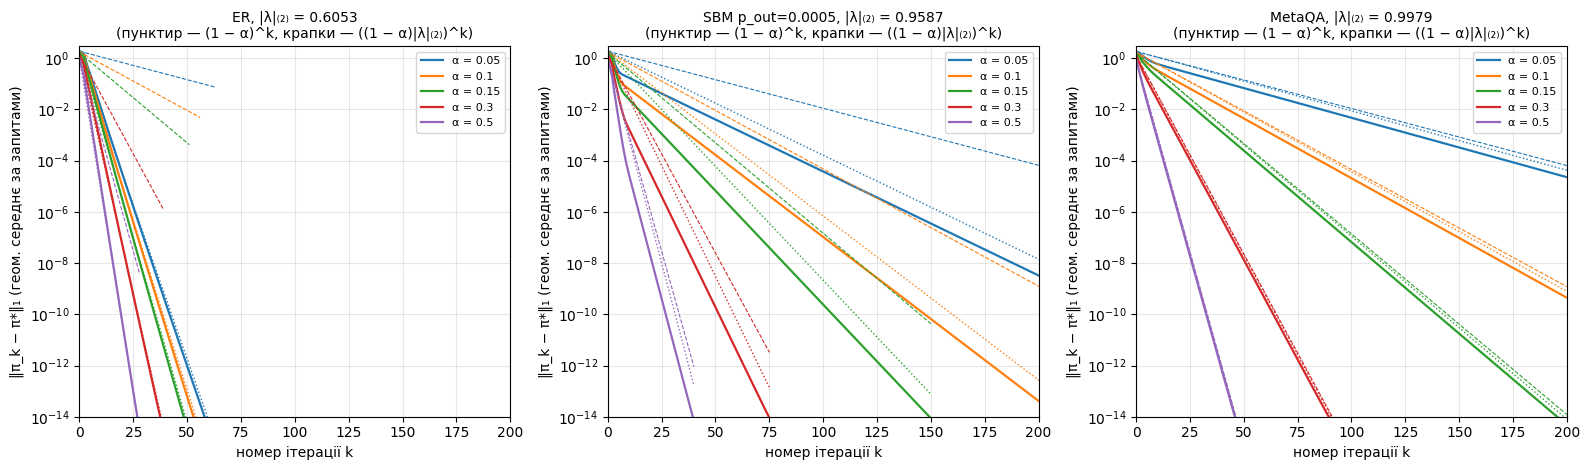

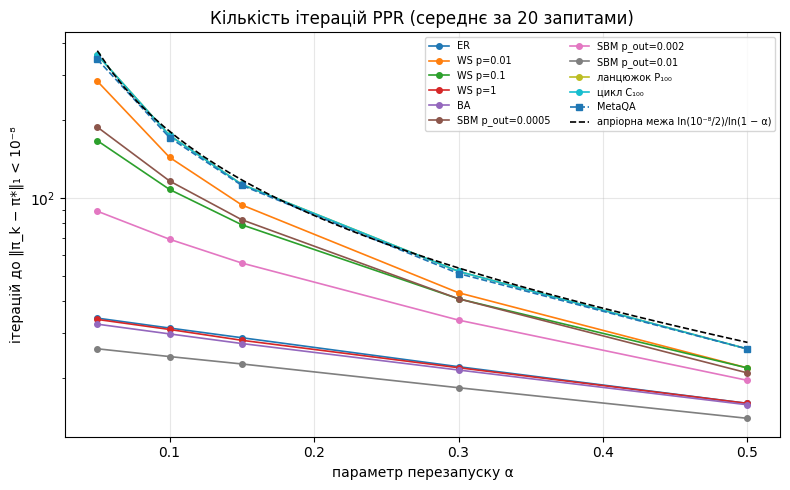

α,0.0500,0.1000,0.1500,0.3000,0.5000
граф,,,,,
ER,34.2000,31.4000,28.8000,22.2000,16.0000
WS p=0.01,283.9000,143.8000,94.0000,43.0000,22.0000
WS p=0.1,167.0000,108.0000,78.8000,40.7000,22.0000
WS p=1,33.8000,31.0000,28.1000,22.0000,16.0000
BA,32.4000,29.8000,27.3000,21.6000,15.8000
SBM p_out=0.0005,188.5000,116.5000,82.4000,40.7000,21.0000
SBM p_out=0.002,89.0000,69.2000,56.0000,33.6000,19.6000
SBM p_out=0.01,26.0000,24.3000,22.8000,18.4000,14.0000
ланцюжок P₁₀₀,359.0000,175.0000,113.0000,52.0000,26.0000


In [7]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, name in zip(axs, ["ER", "SBM p_out=0.0005", "MetaQA"]):
    m2 = SPEC[name][1]["modulus_2"]
    for i, alpha in enumerate(ALPHAS):
        errs = ERR[(name, alpha)]
        K = min(len(e) for e in errs)
        geo = np.exp(np.mean([np.log(np.maximum(e[:K], 1e-300)) for e in errs], axis=0))
        k = np.arange(K)
        ax.semilogy(k, geo, lw=1.6, color=f"C{i}", label=f"α = {alpha}")
        ax.semilogy(k, geo[0] * (1 - alpha) ** k, "--", lw=0.8, color=f"C{i}")
        ax.semilogy(k, geo[0] * ((1 - alpha) * m2) ** k, ":", lw=1.0, color=f"C{i}")
    ax.set_ylim(1e-14, 3); ax.set_xlim(0, 200)
    ax.set_title(f"{name}, |λ|₍₂₎ = {m2:.4f}\n(пунктир — (1 − α)^k, крапки — ((1 − α)|λ|₍₂₎)^k)", fontsize=10)
    ax.set_xlabel("номер ітерації k"); ax.set_ylabel("‖π_k − π*‖₁ (геом. середнє за запитами)")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "01_zbizhnist_ppr_alpha.png", dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for i, name in enumerate(GR):
    sub = tab_ppr[tab_ppr["граф"] == name]
    ax.plot(sub["α"], sub["ітерацій_до_1e8"], "o-" if i < 10 else "s--", ms=4, lw=1.2,
            color=f"C{i % 10}", label=name)
al = np.linspace(0.05, 0.5, 50)
ax.plot(al, np.log(1e-8 / 2) / np.log(1 - al), "k--", lw=1.2, label="апріорна межа ln(10⁻⁸/2)/ln(1 − α)")
ax.set_yscale("log"); ax.set_xlabel("параметр перезапуску α"); ax.set_ylabel("ітерацій до ‖π_k − π*‖₁ < 10⁻⁸")
ax.set_title("Кількість ітерацій PPR (середнє за 20 запитами)"); ax.grid(alpha=0.3); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(FIG / "01_kilkist_iteratsiy.png", dpi=200); plt.show()
display(tab_ppr.pivot_table(index="граф", columns="α", values="ітерацій_до_1e8", sort=False).round(1))

## Завдання 1.3. Збіжність без перезапуску до d/Σd і спектр P

Рахуємо ‖π − d/Σd‖₁ для звичайного блукання (до 3000 кроків), лінивого блукання і теплового ядра. Фактичні швидкості оцінюємо за нахилом і порівнюємо з теорією:
- звичайне блукання — |λ|₍₂₎;
- ліниве — (1 + λ₂)/2;
- теплове ядро — швидкість спадання e^(−(1 − λ₂)) на одиницю часу.

Час перемішування — перший крок (момент), коли похибка < 10⁻³. Порівнюємо його з оцінкою ln(ε₀/10⁻³)/(−ln ρ). Для теплового ядра беремо 5 вузлів запиту: на графах з малою щілиною потрібні великі t.

In [8]:
STEPS = 3000

def fit_rate_tail(err, x, lo=1e-11, hi=1e-2):
    # нахил ln(похибки) на ділянці, де похибка між lo і hi (після перехідного процесу,
    # до рівня округлення); якщо похибка за весь час не впала нижче hi (дуже повільна
    # збіжність) — за другою половиною кривої; якщо не спадає взагалі — NaN
    m = (err > lo) & (err < hi)
    if m.sum() < 5:
        half = x >= x.max() / 2
        if err[half][-1] >= err[half][0] * (1 - 1e-9):
            return np.nan
        m = half & (err > lo)
    return float(np.exp(np.polyfit(x[m], np.log(err[m]), 1)[0]))

def first_below(err, x, eps=1e-3):
    return float(x[np.argmax(err < eps)]) if np.any(err < eps) else np.inf

rows, CURVES = [], {}
for name, g in GR.items():
    s = SPEC[name][1]; pi_inf = stationary(g)
    for kind in ("звичайне", "ліниве"):
        errs = []
        for q in SEEDS[name]:
            tr = rank(g, q, "walk", steps=STEPS, lazy=(kind == "ліниве"), keep_trajectory=True,
                      return_info=True)[1]["trajectory"]
            errs.append(np.abs(tr - pi_inf).sum(axis=1))
        x = np.arange(STEPS + 1, dtype=float)
        theory = s["modulus_2"] if kind == "звичайне" else s["lazy_rate"]
        CURVES[(name, kind)] = (x, errs)
        mix = [first_below(e, x) for e in errs]
        rows.append(dict(граф=name, процес=kind, ρ_виміряна=np.nanmean([fit_rate_tail(e, x) for e in errs]),
                         ρ_теор=theory, час_перемішування=np.mean(mix),
                         оцінка_часу=np.mean([np.log(e[0] / 1e-3) / -np.log(theory) if theory < 1 else np.inf for e in errs]),
                         похибка_в_кінці=np.mean([e[-1] for e in errs])))
    # теплове ядро: t до T, щоб похибка впала приблизно до 1e-12 (не більше 3000)
    T = min(28 / s["gap"], 3000) if s["gap"] > 0 else 3000
    ts = np.linspace(0, T, 31)
    errs = [np.array([np.abs(rank(g, q, "heat", t=t).to_numpy() - pi_inf).sum() for t in ts])
            for q in SEEDS[name][:5]]
    CURVES[(name, "теплове ядро")] = (ts, errs)
    rows.append(dict(граф=name, процес="теплове ядро",
                     ρ_виміряна=np.nanmean([fit_rate_tail(e, ts) for e in errs]),
                     ρ_теор=np.exp(-s["gap"]), час_перемішування=np.mean([first_below(e, ts) for e in errs]),
                     оцінка_часу=np.mean([np.log(e[0] / 1e-3) / s["gap"] for e in errs]),
                     похибка_в_кінці=np.mean([e[-1] for e in errs])))
tab_walk = pd.DataFrame(rows)
tab_walk.to_csv(RES / "01_shvydkist_zbizhnosti_bez_perezapusku.csv", index=False)
pd.set_option("display.float_format", "{:.6g}".format)
display(tab_walk)

/tmp/ipykernel_36357/3591391642.py:31: RuntimeWarning: Mean of empty slice
  rows.append(dict(граф=name, процес=kind, ρ_виміряна=np.nanmean([fit_rate_tail(e, x) for e in errs]),


,граф,процес,ρ_виміряна,ρ_теор,час_перемішування,оцінка_часу,похибка_в_кінці
0,ER,звичайне,0.590507,0.605309,16,15.1388,1.29784e-15
1,ER,ліниве,0.789884,0.799194,34.65,33.9053,8.11042e-16
2,ER,теплове ядро,0.653743,0.66924,20.9157,18.9235,5.61235e-13
3,WS p=0.01,звичайне,0.994572,0.994768,1150.75,1448.92,6.44702e-08
4,WS p=0.01,ліниве,0.997228,0.997384,2304.45,2901.64,0.000194558
5,WS p=0.01,теплове ядро,0.994399,0.994782,1140,1452.72,3.13791e-08
6,WS p=0.1,звичайне,0.949625,0.95198,125.1,154.434,2.02752e-14
7,WS p=0.1,ліниве,0.97479,0.97599,253.2,312.714,4.28334e-15
8,WS p=0.1,теплове ядро,0.950867,0.953115,147.716,158.265,2.25682e-13
9,WS p=1,звичайне,0.585134,0.596609,15.9,14.7145,3.56984e-16


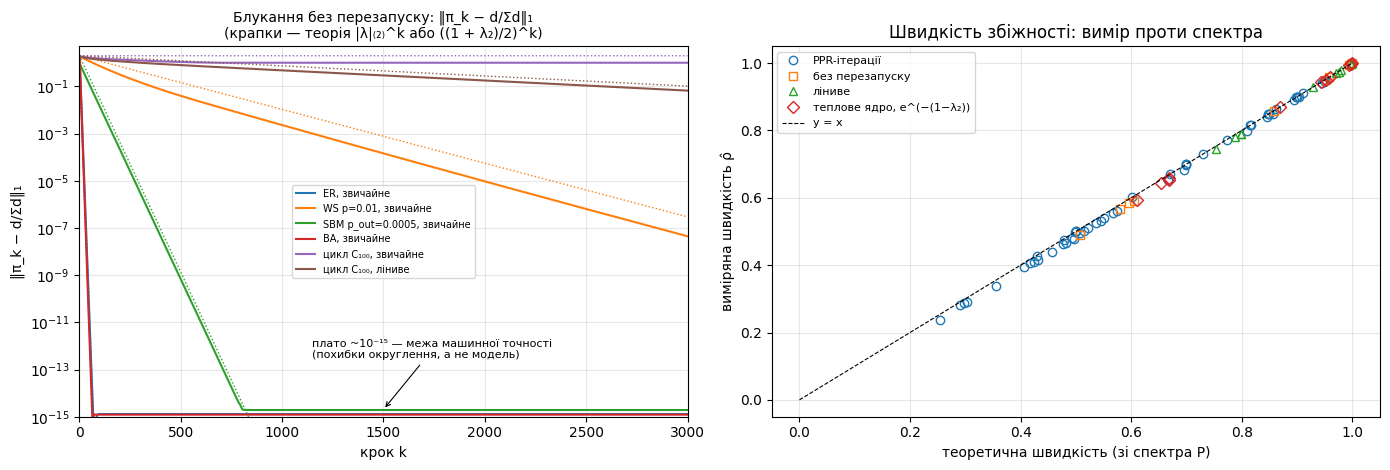

Пар (вимір, теорія) з ρ_теор < 1: 86; макс. |ρ̂ − ρ_теор| = 2.03e-02


In [9]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
for i, (name, kind) in enumerate([("ER", "звичайне"), ("WS p=0.01", "звичайне"), ("SBM p_out=0.0005", "звичайне"),
                                  ("BA", "звичайне"), ("цикл C₁₀₀", "звичайне"), ("цикл C₁₀₀", "ліниве")]):
    x, errs = CURVES[(name, kind)]
    geo = np.exp(np.mean([np.log(np.maximum(e, 1e-300)) for e in errs], axis=0))
    s = SPEC[name][1]; rate = s["modulus_2"] if kind == "звичайне" else s["lazy_rate"]
    axs[0].semilogy(x, geo, lw=1.5, color=f"C{i}", label=f"{name}, {kind}")
    axs[0].semilogy(x, geo[0] * rate ** x, ":", lw=1, color=f"C{i}")
axs[0].set_ylim(1e-15, 5); axs[0].set_xlim(0, 3000)
axs[0].annotate("плато ~10⁻¹⁵ — межа машинної точності\n(похибки округлення, а не модель)",
                xy=(1500, 2e-15), xytext=(1150, 3e-13), fontsize=8, arrowprops=dict(arrowstyle="->", lw=0.8))
axs[0].set_title("Блукання без перезапуску: ‖π_k − d/Σd‖₁\n(крапки — теорія |λ|₍₂₎^k або ((1 + λ₂)/2)^k)", fontsize=10)
axs[0].set_xlabel("крок k"); axs[0].set_ylabel("‖π_k − d/Σd‖₁"); axs[0].legend(fontsize=7)

# Виміряна швидкість проти теоретичної для всіх графів, процесів і α (PPR)
for proc, mk, src in (("PPR-ітерації", "o", tab_ppr), ("без перезапуску", "s", tab_walk[tab_walk["процес"] == "звичайне"]),
                      ("ліниве", "^", tab_walk[tab_walk["процес"] == "ліниве"]),
                      ("теплове ядро, e^(−(1−λ₂))", "D", tab_walk[tab_walk["процес"] == "теплове ядро"])):
    axs[1].plot(src["ρ_теор"], src["ρ_виміряна"], mk, ms=6, mfc="none", label=proc)
axs[1].plot([0, 1], [0, 1], "k--", lw=0.8, label="y = x")
axs[1].set_xlabel("теоретична швидкість (зі спектра P)"); axs[1].set_ylabel("виміряна швидкість ρ̂")
axs[1].set_title("Швидкість збіжності: вимір проти спектра"); axs[1].legend(fontsize=8)
for ax in axs: ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG / "01_shvydkist_vs_spektr.png", dpi=200); plt.show()
both = pd.concat([tab_ppr[["ρ_виміряна", "ρ_теор"]], tab_walk[["ρ_виміряна", "ρ_теор"]]]).dropna()
both = both[both["ρ_теор"] < 0.9999]
print(f"Пар (вимір, теорія) з ρ_теор < 1: {len(both)}; макс. |ρ̂ − ρ_теор| = {(both['ρ_виміряна'] - both['ρ_теор']).abs().max():.2e}")

### MetaQA: майже дводольний граф

Ребра MetaQA з'єднують фільм з атрибутом або людиною, тому граф майже дводольний. Дводольність порушують лише злиті однойменні вузли, наприклад «2012» (і фільм, і рік). Тоді λ_min ≈ −1, і звичайне блукання збігається дуже повільно або коливається. Ліниве блукання і теплове ядро цієї проблеми не мають.

MetaQA: дводольний: False; λ₂ = 0.941452, λ_min = -0.997885, |λ|₍₂₎ = 0.997885, (1 + λ₂)/2 = 0.970726
Найменші 3 власні значення: [-0.919121 -0.941411 -0.997885]
Непарних циклів у базисі циклів: 14; вузли-«фільм + інший тип» у підграфі: ['2012']


Без вузла «2012» (степінь 35): дводольний True, λ_min найбільшої компоненти = -1.000000000


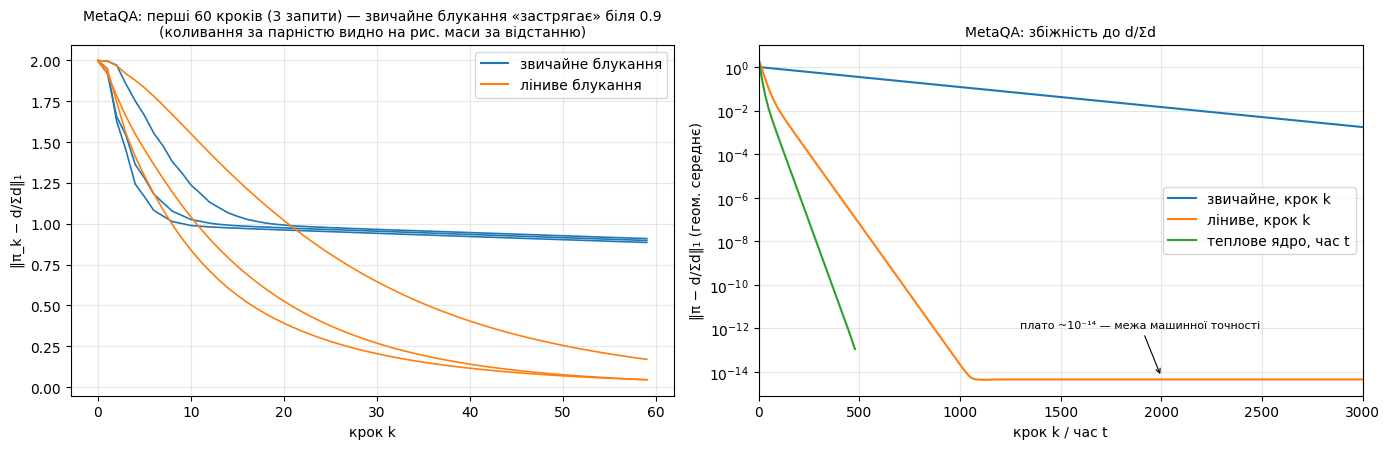

,граф,процес,ρ_виміряна,ρ_теор,час_перемішування,оцінка_часу,похибка_в_кінці
30,MetaQA,звичайне,0.997885,0.997885,inf,3589.78,0.00176734
31,MetaQA,ліниве,0.970655,0.970726,176.2,255.806,4.71345e-15
32,MetaQA,теплове ядро,0.943023,0.943133,95.6478,129.807,1.30898e-13


Без «2012» (строго дводольний): маса однієї частки в d/Σd = 0.500000000000; ‖π_k − d/Σd‖₁ при k = 599, 600: [1. 1. 1.], [1. 1. 1.]
З «2012»: середня похибка при k = 60: 0.8925, |λ_min|^60 = 0.8807; при k = 3000: 1.77e-03, |λ_min|^3000 = 1.74e-03
λ₂ з лінивого блукання: 2ρ̂ − 1 = 0.94131; з теплового ядра: 1 + ln ρ̂ = 0.94134; зі спектра: 0.94145


In [10]:
g = GR["MetaQA"]; s = SPEC["MetaQA"][1]; lam = SPEC["MetaQA"][0]
gs = nx.Graph(g)
odd = [c for c in nx.cycle_basis(gs) if len(c) % 2 == 1]
print(f"MetaQA: дводольний: {nx.is_bipartite(gs)}; λ₂ = {s['lambda_2']:.6f}, λ_min = {s['lambda_min']:.6f}, "
      f"|λ|₍₂₎ = {s['modulus_2']:.6f}, (1 + λ₂)/2 = {s['lazy_rate']:.6f}")
print(f"Найменші 3 власні значення: {np.round(lam[-3:], 6)}")
print(f"Непарних циклів у базисі циклів: {len(odd)}; вузли-«фільм + інший тип» у підграфі: "
      f"{[v for v, k in g.nodes(data='kinds') if 'movie' in k and len(k) > 1]}")
h = g.copy(); h.remove_node("2012")
hb = h.subgraph(max(nx.connected_components(nx.Graph(h)), key=len)).copy()
print(f"Без вузла «2012» (степінь {g.degree('2012')}): дводольний {nx.is_bipartite(nx.Graph(h))}, "
      f"λ_min найбільшої компоненти = {spectrum(hb, return_summary=True)[1]['lambda_min']:.9f}")

fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
x, e_plain = CURVES[("MetaQA", "звичайне")]; _, e_lazy = CURVES[("MetaQA", "ліниве")]
xt, e_heat = CURVES[("MetaQA", "теплове ядро")]
for e in e_plain[:3]:
    axs[0].plot(x[:60], e[:60], lw=1.2, color="C0")
for e in e_lazy[:3]:
    axs[0].plot(x[:60], e[:60], lw=1.2, color="C1")
axs[0].plot([], [], color="C0", label="звичайне блукання"); axs[0].plot([], [], color="C1", label="ліниве блукання")
axs[0].set_title("MetaQA: перші 60 кроків (3 запити) — звичайне блукання «застрягає» біля 0.9\n(коливання за парністю видно на рис. маси за відстанню)", fontsize=10)
axs[0].set_xlabel("крок k"); axs[0].set_ylabel("‖π_k − d/Σd‖₁"); axs[0].legend()
for e, c, lab in ((e_plain, "C0", "звичайне, крок k"), (e_lazy, "C1", "ліниве, крок k")):
    geo = np.exp(np.mean([np.log(np.maximum(v, 1e-300)) for v in e], axis=0))
    axs[1].semilogy(x, geo, color=c, lw=1.5, label=lab)
geo = np.exp(np.mean([np.log(np.maximum(v, 1e-300)) for v in e_heat], axis=0))
axs[1].semilogy(xt, geo, color="C2", lw=1.5, label="теплове ядро, час t")
axs[1].set_xlim(0, 3000); axs[1].set_xlabel("крок k / час t"); axs[1].set_ylabel("‖π − d/Σd‖₁ (геом. середнє)")
axs[1].annotate("плато ~10⁻¹⁴ — межа машинної точності", xy=(2000, 6e-15), xytext=(1300, 1e-12),
                fontsize=8, arrowprops=dict(arrowstyle="->", lw=0.8))
axs[1].set_title("MetaQA: збіжність до d/Σd", fontsize=10); axs[1].legend()
for ax in axs: ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG / "01_metaqa_dvodolnist.png", dpi=200); plt.show()
display(tab_walk[tab_walk["граф"] == "MetaQA"])

# «Плато» ≈ 0.9: у строго дводольному графі кожна частка має в d/Σd рівно 1/2 маси (кожне ребро
# має по кінцю в кожній частці), а блукання з вузла однієї частки на кожному кроці має всю масу
# в одній частці, тому ‖π_k − d/Σd‖₁ ≥ 1 і в границі дорівнює рівно 1.
pi_hb = stationary(hb)
part = nx.bipartite.color(nx.Graph(hb))
mass_A = sum(pi_hb[i] for i, v in enumerate(hb.nodes()) if part[v] == 0)
e_hb = [np.abs(rank(hb, q, "walk", steps=600, keep_trajectory=True, return_info=True)[1]["trajectory"]
               - pi_hb).sum(axis=1) for q in SEEDS["MetaQA"][:3] if q in hb]
print(f"Без «2012» (строго дводольний): маса однієї частки в d/Σd = {mass_A:.12f}; "
      f"‖π_k − d/Σd‖₁ при k = 599, 600: {np.round([e[-2] for e in e_hb], 6)}, {np.round([e[-1] for e in e_hb], 6)}")
lm = s["modulus_2"]
e60 = np.mean([e[60] for e in e_plain]); e3000 = np.mean([e[-1] for e in e_plain])
print(f"З «2012»: середня похибка при k = 60: {e60:.4f}, |λ_min|^60 = {lm ** 60:.4f}; "
      f"при k = 3000: {e3000:.2e}, |λ_min|^3000 = {lm ** 3000:.2e}")
r_lazy = tab_walk[(tab_walk["граф"] == "MetaQA") & (tab_walk["процес"] == "ліниве")]["ρ_виміряна"].item()
r_heat = tab_walk[(tab_walk["граф"] == "MetaQA") & (tab_walk["процес"] == "теплове ядро")]["ρ_виміряна"].item()
print(f"λ₂ з лінивого блукання: 2ρ̂ − 1 = {2 * r_lazy - 1:.5f}; з теплового ядра: 1 + ln ρ̂ = {1 + np.log(r_heat):.5f}; "
      f"зі спектра: {s['lambda_2']:.5f}")

## Завдання 1.4. Спектри і сімейства графів

Гістограми спектрів P, а також залежність щілини 1 − λ₂ і швидкості збіжності від параметра перепідключення WS (p) і від частки міжспільнотних ребер SBM (p_out).

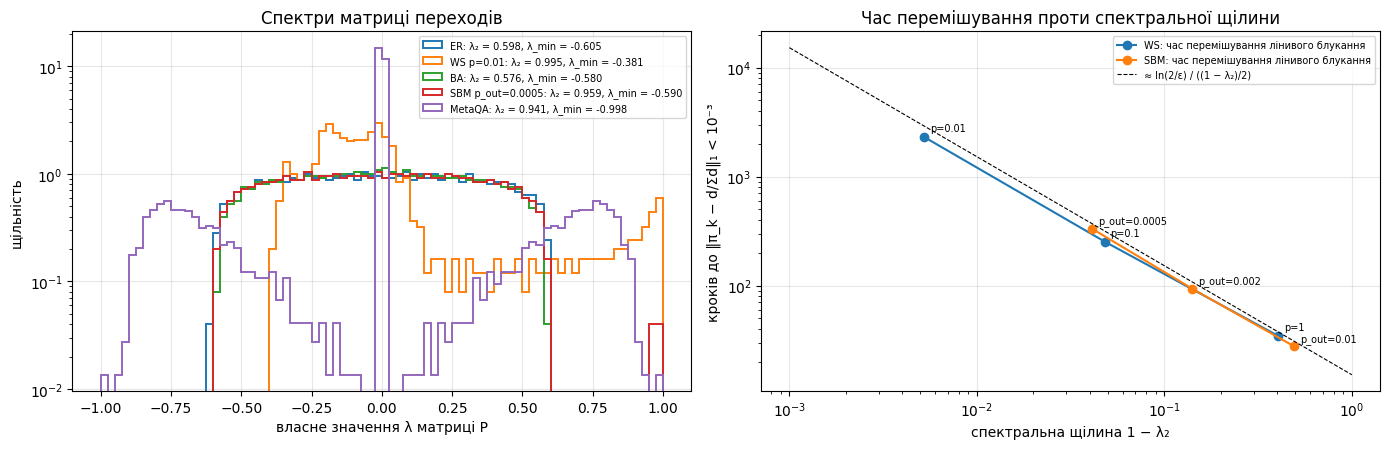

,граф,λ2,λ_min,модуль_λ2,щілина
0,ER,0.598388,-0.605309,0.605309,0.401612
1,WS p=0.01,0.994768,-0.381122,0.994768,0.0052315
2,WS p=0.1,0.95198,-0.465048,0.95198,0.04802
3,WS p=1,0.595905,-0.596609,0.596609,0.404095
4,BA,0.575623,-0.579932,0.579932,0.424377
5,SBM p_out=0.0005,0.958665,-0.589575,0.958665,0.0413353
6,SBM p_out=0.002,0.858911,-0.568407,0.858911,0.141089
7,SBM p_out=0.01,0.506685,-0.49389,0.506685,0.493315
8,ланцюжок P₁₀₀,0.999497,-1,1,0.000503458
9,цикл C₁₀₀,0.998027,-1,1,0.00197327


In [11]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
for i, name in enumerate(["ER", "WS p=0.01", "BA", "SBM p_out=0.0005", "MetaQA"]):
    lam = SPEC[name][0]
    axs[0].hist(lam, bins=80, range=(-1, 1), histtype="step", lw=1.4, density=True, color=f"C{i}",
                label=f"{name}: λ₂ = {lam[1]:.3f}, λ_min = {lam[-1]:.3f}")
axs[0].set_xlabel("власне значення λ матриці P"); axs[0].set_ylabel("щільність")
axs[0].set_yscale("log"); axs[0].set_title("Спектри матриці переходів"); axs[0].legend(fontsize=7)

fam = [("WS", ["WS p=0.01", "WS p=0.1", "WS p=1"]), ("SBM", ["SBM p_out=0.0005", "SBM p_out=0.002", "SBM p_out=0.01"])]
for j, (fname, names) in enumerate(fam):
    gaps = [SPEC[n][1]["gap"] for n in names]
    r_ppr = [tab_ppr[(tab_ppr["граф"] == n) & (tab_ppr["α"] == 0.05)]["ρ_виміряна"].item() for n in names]
    mix = [tab_walk[(tab_walk["граф"] == n) & (tab_walk["процес"] == "ліниве")]["час_перемішування"].item() for n in names]
    axs[1].loglog(gaps, mix, "o-", color=f"C{j}", label=f"{fname}: час перемішування лінивого блукання")
    for n, gp, m in zip(names, gaps, mix):
        axs[1].annotate(n.split(" ")[1], (gp, m), textcoords="offset points", xytext=(4, 4), fontsize=7)
gg = np.logspace(-3, 0, 20)
axs[1].loglog(gg, np.log(2 / 1e-3) / (gg / 2), "k--", lw=0.8, label="≈ ln(2/ε) / ((1 − λ₂)/2)")
axs[1].set_xlabel("спектральна щілина 1 − λ₂"); axs[1].set_ylabel("кроків до ‖π_k − d/Σd‖₁ < 10⁻³")
axs[1].set_title("Час перемішування проти спектральної щілини"); axs[1].legend(fontsize=7)
for ax in axs: ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG / "01_spektry.png", dpi=200); plt.show()
display(tab_spec[["граф", "λ2", "λ_min", "модуль_λ2", "щілина"]])

## Висновки

1. **Швидкість поширення.** Дискретний процес поширюється зі скінченною швидкістю: у 0 випадках π_k мав масу далі ніж k ребер від запиту. Теплове ядро вже при t = 0.5 має ненульову масу в усіх 1000 вузлах ER. При малих t маса на відстані r зростає як t^r: виміряні нахили log M_r від log t дорівнюють 0.975, 1.976, 2.979 і 3.980 для r = 1…4, що узгоджується з першим членом ряду.
2. **Середня відстань у PPR.** Середня відстань маси d̄(π*) значно менша за середню довжину блукання (1 − α)/α, бо блукання повертаються назад. Відношення d̄/((1 − α)/α) становить 0.13–0.16 при α = 0.05, 0.27–0.39 при α = 0.15 і 0.58–0.82 при α = 0.5. Найменше воно на «решітчастих» графах (WS p = 0.01, ланцюжок, цикл), найбільше — на ER і WS p = 1.
3. **Збіжність PPR-ітерацій.** Оцінка ‖π_k − π*‖₁ ≤ (1 − α)^k·‖s − π*‖₁ виконана в усіх 1100 прогонах (11 графів × 5 α × 20 запитів). Фактична швидкість збігається з (1 − α)·|λ|₍₂₎ з медіанним відхиленням 0.8%. Найбільше відхилення, 5.9%, отримано на швидких графах при великих α, і виміряна швидкість тоді нижча за теоретичну (96% випадків). Тому кількість ітерацій визначає не лише α, а й спектр. При α = 0.15 до точності 10⁻⁸ потрібно 23–29 ітерацій на ER, BA і SBM (p_out = 0.01), але 94 на WS (p = 0.01) і 112–113 на MetaQA, ланцюжку та циклі. Останнє близьке до апріорної межі 118, бо там |λ|₍₂₎ ≈ 1.
4. **Без перезапуску.** Збіжність до d/Σd визначає спектр: виміряні швидкості звичайного й лінивого блукання та теплового ядра збігаються з |λ|₍₂₎, (1 + λ₂)/2 і e^(−(1 − λ₂)) з похибкою не більше 0.02 (86 пар). Час перемішування обернено пропорційний щілині 1 − λ₂: ліниве блукання на WS проходить від 34.6 кроку при p = 1 (щілина 0.404) до 2304 кроків при p = 0.01 (щілина 0.0052). Ланцюжок і цикл зі 100 вузлів за 3000 кроків не перемішуються, бо їхні щілини дорівнюють 5·10⁻⁴ і 2·10⁻³. Плато ~10⁻¹⁴–10⁻¹⁵ на кривих похибки — межа машинної точності.
5. **MetaQA майже дводольний.** За таблицею спектрів λ₂ = 0.941452, λ_min = −0.997885. Граф стає точно дводольним (λ_min = −1.000000000), якщо вилучити один злитий вузол «2012» (фільм і рік одночасно). У строго дводольному графі кожне ребро має по кінцю в кожній частці, тому кожна частка має в d/Σd рівно 1/2 маси (перевірено: 0.500000000000). Блукання з вузла однієї частки на кожному кроці тримає всю масу в одній частці, тож ‖π_k − d/Σd‖₁ дорівнює рівно 1 (без «2012»: 1.000000 при k = 599 і 600). З вузлом «2012» це не стале плато: відстань повільно спадає як |λ_min|^k. Середня похибка 0.8925 при k = 60 (|λ_min|^60 = 0.8807) і 1.77·10⁻³ при k = 3000 (|λ_min|^3000 = 1.74·10⁻³). Тобто відхилення від 1 і повільне спадання — наслідок злитих вузлів. Ліниве блукання доходить до 10⁻³ за 176 кроків, теплове ядро — за t ≈ 96. Обидва незалежно дають однакове λ₂: з лінивого 2ρ̂ − 1 = 0.94131, з теплового ядра 1 + ln ρ̂ = 0.94134, зі спектра 0.94145. Висновок: для блукання без перезапуску на MetaQA потрібне ліниве блукання або теплове ядро. PPR цієї проблеми не має, бо (1 − α)·|λ|₍₂₎ < 1.